<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/es_15_HRdiag.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **HR DIAGRAM**

This assignment is about stars...

We will work with a star catalogue of 240 stars described by the following information:

- Temperature (in Kelvin)
- Luminosity (L/Lo)
- Radius (R/Ro)
- Absolute magnitude (Mv)

We also have the following data for each star:

- Color (Red/Orange/Yellow/White/Blue)
- Spectral class ('A', 'B', 'F', 'G', 'K', 'M', 'O')
- Star type (Brown dwarf/Red dwarf/White dwarf/Main sequence/Supergiant/Hypergiant)

In [1]:
import urllib.request
urllib.request.urlretrieve("https://raw.githubusercontent.com/nshaud/ml_for_astro/main/stars.csv", "stars.csv")

('stars.csv', <http.client.HTTPMessage at 0x7f87a8b16850>)

In [2]:
import pandas as pd
df_stars = pd.read_csv("stars.csv")

In [3]:
df_stars

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,Brown Dwarf,Red,M
1,3042,0.000500,0.1542,16.60,Brown Dwarf,Red,M
2,2600,0.000300,0.1020,18.70,Brown Dwarf,Red,M
3,2800,0.000200,0.1600,16.65,Brown Dwarf,Red,M
4,1939,0.000138,0.1030,20.06,Brown Dwarf,Red,M
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,Hypergiant,Blue,O
236,30839,834042.000000,1194.0000,-10.63,Hypergiant,Blue,O
237,8829,537493.000000,1423.0000,-10.73,Hypergiant,White,A
238,9235,404940.000000,1112.0000,-11.23,Hypergiant,White,A


In [4]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# Assign unique integers from 0 to 6 to each star type
df_stars['Star type'] = le.fit_transform(df_stars['Star type'])
labels = le.inverse_transform(df_stars['Star type'])
class_names = le.classes_
print(class_names)

['Brown Dwarf' 'Hypergiant' 'Main Sequence' 'Red Dwarf' 'Supergiant'
 'White Dwarf']


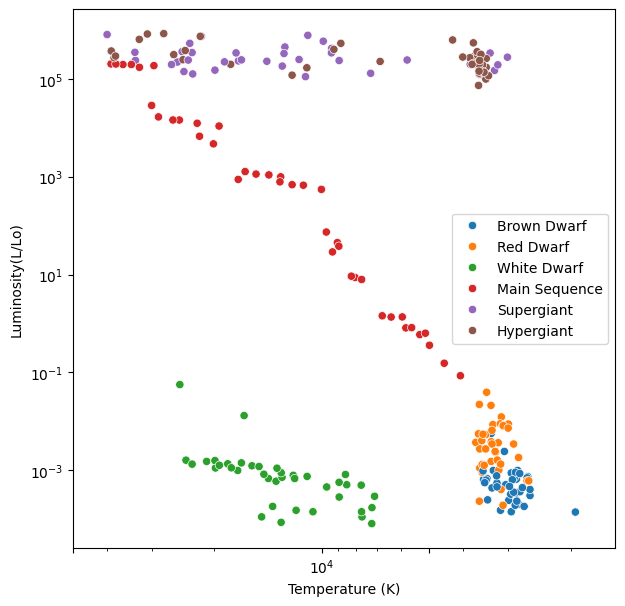

In [5]:
import seaborn as sns
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(7, 7))
sns.scatterplot(data=df_stars, x='Temperature (K)', y='Luminosity(L/Lo)', hue=labels)

plt.xscale('log')
plt.yscale('log')
plt.xticks([5000, 10000, 50000])
plt.xlim(5e4, 1.5e3)
plt.show()

- Apply PCA to the dataset at your disposal (hint: don't use columns with labels, only those with real numbers).
- Project the dataset into the principal components, and do a scatter plot of the first two.
- This will look terrible. Think about the units!
- Explore what happens if you rescale the data first.

**This is actually a very important lesson in machine learning**: Massaging your data before giving them to an algorithm can make things much much better.

- You can try an linear, affine transformation such that each dimension goes between -1 and 1.
- Or (which is [the usual machine-learning approach](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)) standardize your data such that each dimension has mean=0 and variance=1.
- Redo your PCA. Should be much much better.
- How much variance is explained by those two components?

In [6]:
import numpy as np
Temp =np.array(df_stars['Temperature (K)'] )
Lumi=np.array(df_stars['Luminosity(L/Lo)'])
Radius= np.array(df_stars['Radius(R/Ro)'])
Magnitude = np.array(df_stars['Absolute magnitude(Mv)'])
Stars_4d= np.array([Temp,Lumi,Radius,Magnitude]).T
print(Stars_4d.shape) #should be in the form NxK
#vedere se struttura con pandas è meglio

(240, 4)


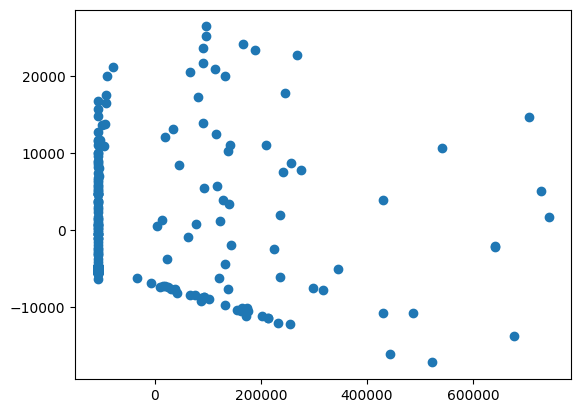

In [7]:
from sklearn.decomposition import PCA
from matplotlib import pyplot as plt
def pca_redu(r,data):
  pca = PCA(n_components=r)
  pca.fit(data)
  data_pca = pca.transform(data)
  return data_pca,pca.explained_variance_ratio_


r=2
Stars_pca,variance_ration=pca_redu(r,Stars_4d)
plt.scatter(Stars_pca[:,0],Stars_pca[:,1])


*  PREPROCESSING DATA



In [29]:
#with standard scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Stars_scaled = scaler.fit_transform(Stars_4d)




*  COMULATIVE VARIANCE



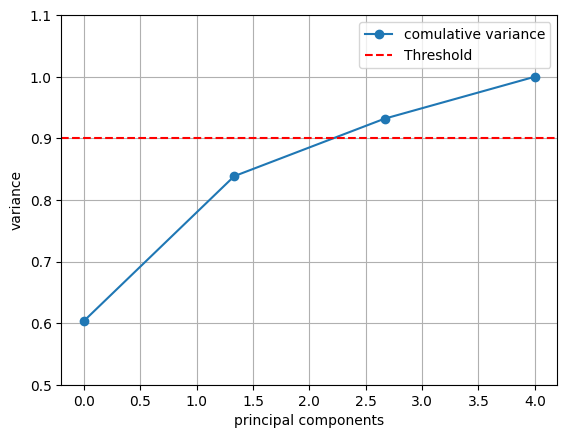

In [30]:
variance_ratio_com_arr=[]
variance_ratio_com=0
Stars_scaled_pca,variance_ratio=pca_redu(4,Stars_scaled)
for i in range(len(variance_ratio)):
  variance_ratio_com=variance_ratio[i]+variance_ratio_com
  variance_ratio_com_arr.append(variance_ratio_com)

plt.plot(np.linspace(0,4,4),variance_ratio_com_arr,label='comulative variance', marker='o')
plt.grid(':')
plt.ylim(0.5, 1.1)
plt.axhline(y=0.9, color="r", linestyle="--", label="Threshold")
plt.xlabel('principal components')
plt.ylabel('variance')

plt.legend()
plt.show()

PCA

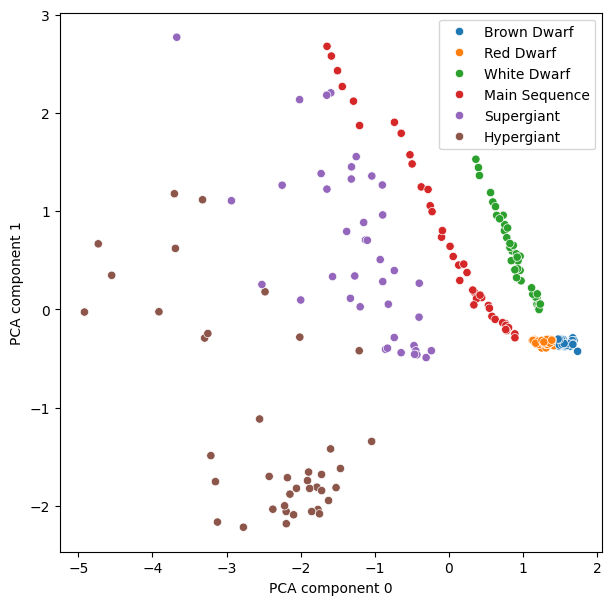

In [32]:
#PCA
Stars_scaled_pca,variance_ratio=pca_redu(3,Stars_scaled)
fig = plt.figure(figsize=(7, 7))
sns.scatterplot(x=Stars_scaled_pca[:,0],y=Stars_scaled_pca[:,1],hue=labels)
plt.xlabel("PCA component 0")
plt.ylabel("PCA component 1")

plt.show()

lo standard scaler sulle 4 features ha difficoltà a lavoare perchè le prime 3 grandezze sono lineari invece la quarta è logarimica

In [35]:
Stars_4d_log= np.array([np.log(Temp),np.log(Lumi),np.log(Radius),Magnitude]).T

In [36]:
Stars_scaled_log = scaler.fit_transform(Stars_4d_log)


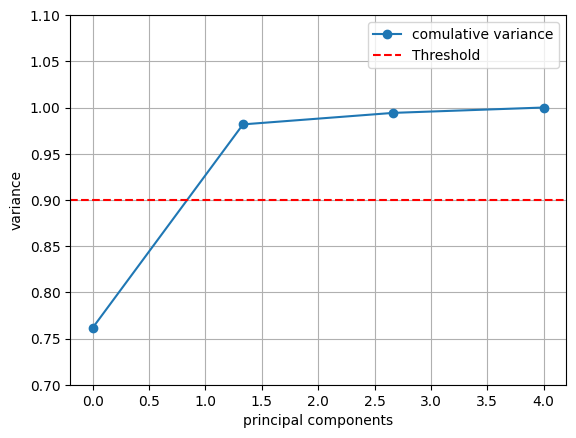

In [40]:
variance_ratio_com_arr_log=[]
variance_ratio_com_log=0
Stars_scaled_pca_log,variance_ratio_log=pca_redu(4,Stars_scaled_log)
for i in range(len(variance_ratio_log)):
  variance_ratio_com_log=variance_ratio_log[i]+variance_ratio_com_log
  variance_ratio_com_arr_log.append(variance_ratio_com_log)

plt.plot(np.linspace(0,4,4),variance_ratio_com_arr_log,label='comulative variance', marker='o')
plt.grid(':')
plt.ylim(0.7, 1.1)
plt.axhline(y=0.9, color="r", linestyle="--", label="Threshold")
plt.xlabel('principal components')
plt.ylabel('variance')

plt.legend()
plt.show()

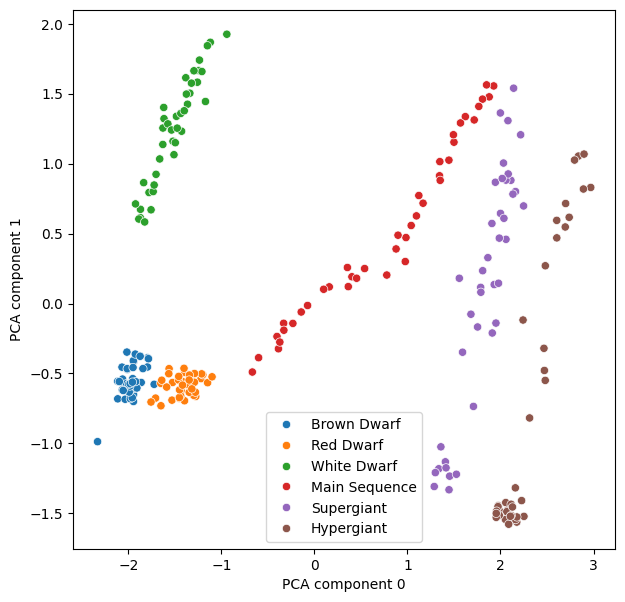

In [38]:
#PCA
Stars_scaled_pca_log,variance_ratio=pca_redu(2,Stars_scaled_log)

fig = plt.figure(figsize=(7, 7))
sns.scatterplot(x=Stars_scaled_pca_log[:,0],y=Stars_scaled_pca_log[:,1],hue=labels)
plt.xlabel("PCA component 0")
plt.ylabel("PCA component 1")

plt.show()

In [41]:
print(f'the first 2 components explain the {variance_ratio_com_arr_log[2]:.2f}% of the variance')

the first 2 components explain the 0.99% of the variance
